<a href="https://colab.research.google.com/github/Madz2681/beginning-bioinformatics/blob/main/Final_Project_BioInfo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import Python Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler

print("Yippee! libraries imported successfully")


Yippee! libraries imported successfully


In [ ]:
# Download Data Sets

import urllib.request

# Training dataset
train_url = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE36nnn/GSE36761/suppl/"
    "GSE36761_gene_expression_levels_normalized.txt.gz"
)

# Testing dataset
test_url = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE217nnn/GSE217772/suppl/"
    "GSE217772_mRNA_count.txt.gz"
)

urllib.request.urlretrieve(
    train_url, "GSE36761.txt.gz"
)

urllib.request.urlretrieve(
    test_url, "GSE217772.txt.gz"
)

print("Both datasets downloaded!")

Both datasets downloaded!


In [ ]:
# Examine Data Organization

train_raw = pd.read_csv(
    "GSE36761.txt.gz",
    sep="\t",
    compression="gzip"
)

test_raw = pd.read_csv(
    "GSE217772.txt.gz",
    sep="\t",
    compression="gzip"
)

print("TRAINING DATA:")
print("Shape:", train_raw.shape)
print("Columns:", train_raw.columns.tolist()[:15])
display(train_raw.head())

print("\nTESTING DATA:")
print("Shape:", test_raw.shape)
print("Columns:", test_raw.columns.tolist()[:15])
display(test_raw.head())


TRAINING DATA:
Shape: (26521, 31)
Columns: ['Ensembl Gene ID', 'NH-03', 'NH-05', 'NH-06', 'NH-07', 'NH-01', 'NH-02', 'NH-04', 'NH-08', 'TOF-04', 'TOF-05', 'TOF-18', 'TOF-19', 'TOF-07', 'TOF-08']


,Ensembl Gene ID,NH-03,NH-05,NH-06,NH-07,NH-01,NH-02,NH-04,NH-08,TOF-04,...,TOF-06,TOF-10,TOF-02,TOF-11,TOF-12,TOF-21,TOF-16,TOF-17,TOF-20,TOF-22
0,ENSG00000000003,48.313735,60.472964,65.560726,57.832600,44.459296,48.999313,50.097956,85.650338,66.972413,...,87.802583,112.193728,48.895986,134.765306,72.975257,64.548296,45.043265,79.525748,117.292231,80.099925
1,ENSG00000000005,0.007349,1.667354,0.000000,0.000000,0.010907,0.009290,0.018075,0.000000,0.728567,...,0.781473,12.853480,6.096284,0.004110,0.115630,0.022739,2.211857,1.454636,1.844157,0.000000
2,ENSG00000000419,124.184226,153.039079,113.167961,190.221189,198.450738,173.120112,128.698944,187.272980,142.061768,...,223.752669,236.004261,128.336057,431.662074,157.320218,112.955731,82.363183,131.475656,241.058629,166.549292
3,ENSG00000000457,63.214291,47.721774,31.421542,61.812024,53.053628,57.326700,65.685737,78.851608,81.571536,...,70.900607,72.669722,42.785208,95.250551,88.540610,89.246702,35.171688,65.740178,121.034964,109.580416
4,ENSG00000000460,13.800901,10.380942,10.171227,18.287283,7.502413,10.795559,11.518964,23.838996,17.728497,...,19.400552,28.752501,14.265225,25.330923,20.043607,17.223147,4.453078,5.969232,36.353518,24.625345



TESTING DATA:
Shape: (18497, 11)
Columns: ['gene_id', 'treat1', 'treat3', 'control4', 'treat2', 'treat5', 'control2', 'control3', 'control1', 'control5', 'treat4']


,gene_id,treat1,treat3,control4,treat2,treat5,control2,control3,control1,control5,treat4
0,ENSG00000000003,123,50,103,105,88,71,74,72,81,57
1,ENSG00000000005,11,0,1,1,3,0,2,0,0,4
2,ENSG00000000419,563,201,244,349,298,186,214,181,179,257
3,ENSG00000000457,379,274,421,410,456,327,446,551,418,274
4,ENSG00000000460,97,45,93,88,99,70,115,95,106,93


In [ ]:

# Rename gene ID columns so they match
train = train_raw.rename(
    columns={"Ensembl Gene ID": "gene_id"}
).copy()

test = test_raw.copy()

# Remove version numbers from Ensembl IDs, if present
train["gene_id"] = train["gene_id"].astype(str).str.split(".").str[0]
test["gene_id"] = test["gene_id"].astype(str).str.split(".").str[0]

# Remove duplicate gene IDs
train = train.drop_duplicates(subset="gene_id")
test = test.drop_duplicates(subset="gene_id")

# Identify genes present in both datasets
common_genes = sorted(
    set(train["gene_id"]) & set(test["gene_id"])
)

# Keep only matching genes
train_matched = (
    train.set_index("gene_id")
    .loc[common_genes]
)

test_matched = (
    test.set_index("gene_id")
    .loc[common_genes]
)

print("Genes in training:", len(train))
print("Genes in testing:", len(test))
print("Genes shared:", len(common_genes))

print("Training shape:", train_matched.shape)
print("Testing shape:", test_matched.shape)


Genes in training: 26521
Genes in testing: 18445
Genes shared: 16385
Training shape: (16385, 30)
Testing shape: (16385, 10)


In [ ]:

# Display all sample names in the training dataset
print("Training sample names:")

for sample in train_matched.columns:
    print(sample)

Training sample names:
NH-03
NH-05
NH-06
NH-07
NH-01
NH-02
NH-04
NH-08
TOF-04
TOF-05
TOF-18
TOF-19
TOF-07
TOF-08
TOF-09
TOF-13
TOF-14
TOF-15
TOF-01
TOF-03
TOF-06
TOF-10
TOF-02
TOF-11
TOF-12
TOF-21
TOF-16
TOF-17
TOF-20
TOF-22


In [ ]:
# Select the four right ventricular controls
control_samples = ["NH-02", "NH-04", "NH-06", "NH-08"]

# Select all TOF samples
tof_samples = [
    col for col in train_matched.columns
    if col.startswith("TOF-")
]

# Keep only the correct training samples
train_filtered = train_matched[
    control_samples + tof_samples
].copy()

print("Training shape:", train_filtered.shape)
print("Controls:", len(control_samples))
print("TOF patients:", len(tof_samples))

display(train_filtered.head())


Training shape: (16385, 26)
Controls: 4
TOF patients: 22


,NH-02,NH-04,NH-06,NH-08,TOF-04,TOF-05,TOF-18,TOF-19,TOF-07,TOF-08,...,TOF-06,TOF-10,TOF-02,TOF-11,TOF-12,TOF-21,TOF-16,TOF-17,TOF-20,TOF-22
gene_id,,,,,,,,,,,,,,,,,,,,,
ENSG00000000003,48.999313,50.097956,65.560726,85.650338,66.972413,45.001672,57.326532,56.204706,72.418799,96.014561,...,87.802583,112.193728,48.895986,134.765306,72.975257,64.548296,45.043265,79.525748,117.292231,80.099925
ENSG00000000005,0.009290,0.018075,0.000000,0.000000,0.728567,1.416475,6.194461,1.136811,7.034474,0.092625,...,0.781473,12.853480,6.096284,0.004110,0.115630,0.022739,2.211857,1.454636,1.844157,0.000000
ENSG00000000419,173.120112,128.698944,113.167961,187.272980,142.061768,141.207851,308.717856,84.857846,126.733210,156.170458,...,223.752669,236.004261,128.336057,431.662074,157.320218,112.955731,82.363183,131.475656,241.058629,166.549292
ENSG00000000457,57.326700,65.685737,31.421542,78.851608,81.571536,67.305052,9.469463,23.194510,72.418104,89.322846,...,70.900607,72.669722,42.785208,95.250551,88.540610,89.246702,35.171688,65.740178,121.034964,109.580416
ENSG00000000460,10.795559,11.518964,10.171227,23.838996,17.728497,22.405043,2.521294,14.351467,12.072167,26.593027,...,19.400552,28.752501,14.265225,25.330923,20.043607,17.223147,4.453078,5.969232,36.353518,24.625345


In [ ]:
# Remove genes with very low expression in most training samples

# Keep genes with expression greater than 1
# in at least 20% of training samples
min_samples = int(np.ceil(0.20 * train_filtered.shape[1]))

genes_to_keep = (
    (train_filtered > 1).sum(axis=1) >= min_samples
)

# Filter training data
train_expression = train_filtered.loc[genes_to_keep].copy()

# Keep the same genes in the testing dataset
test_expression = test_matched.loc[train_expression.index].copy()

print("Genes before filtering:", train_filtered.shape[0])
print("Genes after filtering:", train_expression.shape[0])
print("Training shape:", train_expression.shape)
print("Testing shape:", test_expression.shape)


Genes before filtering: 16385
Genes after filtering: 14985
Training shape: (14985, 26)
Testing shape: (14985, 10)


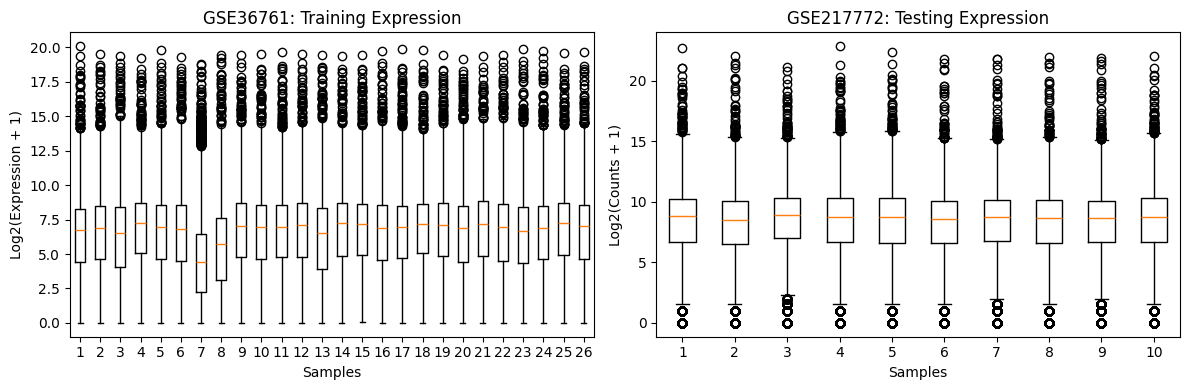

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
from google.colab import files

# Apply log transformation for visualization
train_log = np.log2(train_expression + 1)
test_log = np.log2(test_expression + 1)

# Create boxplots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Training dataset
axes[0].boxplot(train_log.values)
axes[0].set_title("GSE36761: Training Expression")
axes[0].set_ylabel("Log2(Expression + 1)")
axes[0].set_xlabel("Samples")

# Testing dataset
axes[1].boxplot(test_log.values)
axes[1].set_title("GSE217772: Testing Expression")
axes[1].set_ylabel("Log2(Counts + 1)")
axes[1].set_xlabel("Samples")

plt.tight_layout()

# Save high-resolution image
filename = "TOF_Expression_Boxplots.png"
plt.savefig(filename, dpi=300, bbox_inches="tight")

# Display plots
plt.show()

# Download image to your computer
files.download(filename)

In [ ]:

# Calculate summary statistics for each dataset
train_summary = train_log.describe().loc[
    ["mean", "std", "min", "25%", "50%", "75%", "max"]
]

test_summary = test_log.describe().loc[
    ["mean", "std", "min", "25%", "50%", "75%", "max"]
]

print("TRAINING DATA SUMMARY:")
display(train_summary)

print("\nTESTING DATA SUMMARY:")
display(test_summary)

TRAINING DATA SUMMARY:


,NH-02,NH-04,NH-06,NH-08,TOF-04,TOF-05,TOF-18,TOF-19,TOF-07,TOF-08,...,TOF-06,TOF-10,TOF-02,TOF-11,TOF-12,TOF-21,TOF-16,TOF-17,TOF-20,TOF-22
mean,6.274419e+00,6.454654e+00,6.161041,6.752245,6.483736,6.429501,4.577717,5.446157,6.641890,6.483130,...,6.482397,6.705337,6.655368,6.344413,6.701850,6.450884,6.328052,6.438898,6.697472,6.479321
std,2.922571e+00,2.915768e+00,3.110056,2.831462,2.975045,3.024319,3.093837,3.096290,2.964078,3.001493,...,2.914314,2.825051,2.942770,3.085021,3.014528,3.055381,2.976074,2.952811,2.914846,2.984009
min,7.214001e-10,1.389346e-09,0.000000,0.000000,0.000000,0.018967,0.000000,0.005722,0.000420,0.016399,...,0.000000,0.000000,0.001105,0.000801,0.024067,0.004336,0.005517,0.000000,0.000000,0.000000
25%,4.420848e+00,4.649127e+00,4.023875,5.091749,4.609764,4.475261,2.216693,3.134273,4.814929,4.627807,...,4.716136,5.055017,4.883339,4.409624,4.822058,4.493356,4.380092,4.621134,4.944456,4.627595
50%,6.712597e+00,6.895977e+00,6.523747,7.229675,6.988336,6.852702,4.444283,5.753105,7.063574,6.996851,...,6.986578,7.194313,7.103116,6.876913,7.182758,6.961964,6.702696,6.891063,7.254135,7.018561
75%,8.293817e+00,8.484755e+00,8.419909,8.686587,8.571945,8.588259,6.471085,7.646682,8.729432,8.584956,...,8.510935,8.648018,8.716355,8.486554,8.833513,8.616484,8.446501,8.499758,8.719918,8.579561
max,2.009351e+01,1.949183e+01,19.399440,19.242506,19.781285,19.272865,18.814340,19.434933,19.431047,19.516801,...,19.891468,19.780883,19.439423,19.171333,19.379049,19.473905,19.889594,19.723397,19.614271,19.655151



TESTING DATA SUMMARY:


,treat1,treat3,control4,treat2,treat5,control2,control3,control1,control5,treat4
mean,8.192903,7.997781,8.434951,8.205651,8.207015,8.067084,8.245042,8.153019,8.146763,8.259965
std,3.121371,3.053524,2.870160,3.135652,3.093014,2.935275,2.870329,2.941336,2.900858,3.011939
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6.672425,6.475733,7.011227,6.643856,6.584963,6.569856,6.794416,6.629357,6.686501,6.672425
50%,8.794416,8.495855,8.918863,8.781360,8.754888,8.550747,8.734710,8.665336,8.647458,8.784635
75%,10.251482,10.033423,10.327553,10.307201,10.284246,10.034799,10.142107,10.113742,10.063395,10.280771
max,22.714439,22.025908,21.130584,22.852345,22.394639,21.794241,21.781262,21.917902,21.887833,22.060442


In [ ]:

# Calculate total counts for each testing sample
test_total_counts = test_expression.sum(axis=0)

print("Total counts per testing sample:")
display(test_total_counts.to_frame(name="Total Counts"))

print("\nHighest / lowest total count ratio:")
print(round(test_total_counts.max() / test_total_counts.min(), 2))


Total counts per testing sample:


,Total Counts
treat1,42153584
treat3,37734094
control4,31371627
treat2,43198111
treat5,39685033
control2,33382149
control3,36524174
control1,36324781
control5,35191499
treat4,36558208



Highest / lowest total count ratio:
1.38


In [ ]:

# Step 7: Normalize testing data using CPM

# Start with the original testing count matrix
test_counts = test.set_index("gene_id").copy()

# Calculate total counts per sample
library_sizes = test_counts.sum(axis=0)

# Normalize counts per million
test_cpm = test_counts.div(library_sizes, axis=1) * 1_000_000

# Keep only the genes selected during training preprocessing
test_cpm = test_cpm.loc[train_expression.index]

# Log-transform the normalized values
test_cpm_log = np.log2(test_cpm + 1)

print("Testing shape:", test_cpm_log.shape)
print("\nMedian log2 CPM for each sample:")
display(test_cpm_log.median().round(2))


Testing shape: (14985, 10)

Median log2 CPM for each sample:


,0
treat1,3.50
treat3,3.37
control4,4.00
treat2,3.46
treat5,3.54
control2,3.57
control3,3.63
control1,3.57
control5,3.60
treat4,3.68


Spearman correlation: 0.828
P-value: 0.0


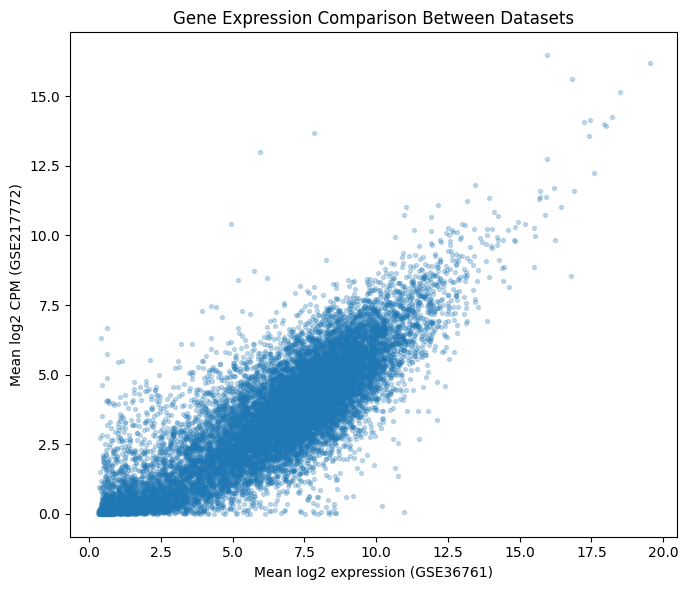

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from scipy.stats import spearmanr
import matplotlib.pyplot as plt

# Calculate average expression for each gene
train_gene_mean = train_log.mean(axis=1)
test_gene_mean = test_cpm_log.mean(axis=1)

# Calculate Spearman correlation
correlation, p_value = spearmanr(
    train_gene_mean,
    test_gene_mean
)

print("Spearman correlation:", round(correlation, 3))
print("P-value:", p_value)

# Create scatter plot
plt.figure(figsize=(7, 6))

plt.scatter(
    train_gene_mean,
    test_gene_mean,
    alpha=0.25,
    s=8
)

plt.xlabel("Mean log2 expression (GSE36761)")
plt.ylabel("Mean log2 CPM (GSE217772)")
plt.title("Gene Expression Comparison Between Datasets")

plt.tight_layout()

# Save and download the figure
filename = "TOF_Gene_Expression_Comparison.png"
plt.savefig(filename, dpi=300, bbox_inches="tight")

plt.show()

from google.colab import files
files.download(filename)

In [ ]:
 # Feature Selection

from sklearn.feature_selection import SelectKBest, f_classif
import pandas as pd
import numpy as np

# Use log-transformed training expression values
X_train = np.log2(train_filtered + 1).T

# Create labels: 0 = control, 1 = TOF
y_train = np.array([
    0 if sample.startswith("NH-") else 1
    for sample in X_train.index
])

# Rank genes using an ANOVA F-test
selector = SelectKBest(
    score_func=f_classif,
    k=20
)

selector.fit(X_train, y_train)

# Get the selected gene IDs
selected_genes = X_train.columns[
    selector.get_support()
]

# Create a table of selected genes and scores
feature_scores = pd.DataFrame({
    "Gene ID": X_train.columns,
    "F-score": selector.scores_,
    "P-value": selector.pvalues_
})

top_genes = (
    feature_scores
    .sort_values("F-score", ascending=False)
    .head(20)
)

print("Top 20 genes associated with TOF:")
display(top_genes)

# Save results
top_genes.to_csv(
    "TOF_Top_20_Genes.csv",
    index=False
)

from google.colab import files
files.download("TOF_Top_20_Genes.csv")


Top 20 genes associated with TOF:


,Gene ID,F-score,P-value
9526,ENSG00000157856,600.541549,1.701981e-18
10008,ENSG00000162009,473.300210,2.632211e-17
2563,ENSG00000102452,296.446494,5.204059e-15
5317,ENSG00000124875,197.950937,4.341189e-13
5320,ENSG00000124935,185.939766,8.490620e-13
12207,ENSG00000171903,184.017578,9.486644e-13
6602,ENSG00000134986,161.441334,3.793260e-12
6628,ENSG00000135116,160.091184,4.142970e-12
9679,ENSG00000159173,153.778930,6.312523e-12
12206,ENSG00000171885,125.270816,5.212697e-11


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Feature Selection

# Step 10: Determine expression direction for top genes

# Calculate average log2 expression for each group
control_mean = X_train.loc[
    y_train == 0
].mean(axis=0)

tof_mean = X_train.loc[
    y_train == 1
].mean(axis=0)

# Add expression differences to the top genes table
top_genes["Control Mean"] = top_genes["Gene ID"].map(control_mean)
top_genes["TOF Mean"] = top_genes["Gene ID"].map(tof_mean)

top_genes["Log2 Difference"] = (
    top_genes["TOF Mean"] - top_genes["Control Mean"]
)

top_genes["Direction"] = np.where(
    top_genes["Log2 Difference"] > 0,
    "Higher in TOF",
    "Lower in TOF"
)

display(top_genes)

# Save updated results
top_genes.to_csv(
    "TOF_Top_20_Genes_With_Direction.csv",
    index=False
)

from google.colab import files
files.download("TOF_Top_20_Genes_With_Direction.csv")


,Gene ID,F-score,P-value,Control Mean,TOF Mean,Log2 Difference,Direction
9526,ENSG00000157856,600.541549,1.701981e-18,1.684305,3.263750e-10,-1.684305,Lower in TOF
10008,ENSG00000162009,473.300210,2.632211e-17,6.168099,1.807081e-01,-5.987391,Lower in TOF
2563,ENSG00000102452,296.446494,5.204059e-15,5.748777,2.834514e-01,-5.465326,Lower in TOF
5317,ENSG00000124875,197.950937,4.341189e-13,1.593080,3.263750e-10,-1.593080,Lower in TOF
5320,ENSG00000124935,185.939766,8.490620e-13,3.271284,1.548664e-01,-3.116418,Lower in TOF
12207,ENSG00000171903,184.017578,9.486644e-13,2.993060,1.166949e-01,-2.876365,Lower in TOF
6602,ENSG00000134986,161.441334,3.793260e-12,6.113131,1.110687e+01,4.993736,Higher in TOF
6628,ENSG00000135116,160.091184,4.142970e-12,0.005298,3.450308e+00,3.445010,Higher in TOF
9679,ENSG00000159173,153.778930,6.312523e-12,7.454093,1.317017e+01,5.716076,Higher in TOF
12206,ENSG00000171885,125.270816,5.212697e-11,6.833622,5.926195e-01,-6.241002,Lower in TOF


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Feature Selection

# Step 11: GWAS-informed feature selection

import pandas as pd

# Candidate genes from TOF-associated genomic regions
# This is a starting candidate list, not a complete GWAS gene set.
gwas_genes = [
    "GPC5"
]

# Convert Ensembl IDs to gene symbols using MyGene.info
!pip -q install mygene

import mygene
mg = mygene.MyGeneInfo()

gene_ids = train_expression.index.tolist()

results = mg.querymany(
    gene_ids,
    scopes="ensembl.gene",
    fields="symbol",
    species="human",
    as_dataframe=False,
    verbose=False
)

# Create a mapping from Ensembl IDs to gene symbols
gene_mapping = pd.DataFrame(results)

gene_mapping = gene_mapping[
    ["query", "symbol"]
].dropna().drop_duplicates(subset="query")

gene_mapping.columns = ["Gene ID", "Gene Symbol"]

# Find genes in the GWAS candidate list
gwas_selected = gene_mapping[
    gene_mapping["Gene Symbol"].isin(gwas_genes)
].copy()

print("GWAS candidate genes found in expression data:")
display(gwas_selected)

print("\nNumber of GWAS candidate genes found:",
      len(gwas_selected))

# Save selected genes
gwas_selected.to_csv(
    "TOF_GWAS_Selected_Genes.csv",
    index=False
)

from google.colab import files
files.download("TOF_GWAS_Selected_Genes.csv")


GWAS candidate genes found in expression data:


,Gene ID,Gene Symbol



Number of GWAS candidate genes found: 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Check whether GPC5 is present in our datasets

# Look up the Ensembl ID for GPC5
gpc5_result = mg.query(
    "symbol:GPC5",
    species="human",
    fields="ensembl.gene"
)

print("GPC5 database result:")
print(gpc5_result)

# Check how many gene IDs were mapped successfully
print("\nTotal genes mapped to symbols:",
      len(gene_mapping))

print("\nFirst 10 mapped genes:")
display(gene_mapping.head(10))

# Check for GPC5 in the mapped genes
print("\nGPC5 matches:")
display(
    gene_mapping[
        gene_mapping["Gene Symbol"] == "GPC5"
    ]
)


GPC5 database result:
{'took': 3, 'total': 1, 'max_score': 18.46423, 'hits': [{'_id': '2262', '_score': 18.46423, 'ensembl': {'gene': 'ENSG00000179399'}}]}

Total genes mapped to symbols: 14969

First 10 mapped genes:


,Gene ID,Gene Symbol
0,ENSG00000000003,TSPAN6
1,ENSG00000000005,TNMD
2,ENSG00000000419,DPM1
3,ENSG00000000457,SCYL3
4,ENSG00000000460,FIRRM
5,ENSG00000000938,FGR
6,ENSG00000000971,CFH
7,ENSG00000001036,FUCA2
8,ENSG00000001084,GCLC
9,ENSG00000001167,NFYA



GPC5 matches:


,Gene ID,Gene Symbol


In [ ]:

# Check whether GPC5 was present before filtering

gpc5_id = "ENSG00000179399"

print("GPC5 in original training data:",
      gpc5_id in train.index)

print("GPC5 in matched training data:",
      gpc5_id in train_matched.index)

print("GPC5 in filtered training data:",
      gpc5_id in train_expression.index)

print("GPC5 in testing data:",
      gpc5_id in test.index)

# If present in original training data, show its expression
if gpc5_id in train.index:
    print("\nGPC5 expression in original training data:")
    display(train.loc[gpc5_id] if train.index.name == "gene_id"
            else train[train["gene_id"] == gpc5_id])


GPC5 in original training data: False
GPC5 in matched training data: True
GPC5 in filtered training data: False
GPC5 in testing data: False


In [ ]:

# Step 11C: Match GWAS candidates to RNA-seq data

import pandas as pd

# Candidates from Cordell et al. (2013)
gwas_candidates = pd.DataFrame({
    "Gene Symbol": ["GPC5", "PTPN11", "NRP1"],
    "Evidence": [
        "Replicated GWAS locus",
        "Candidate within replicated GWAS locus",
        "Suggestive GWAS locus"
    ],
    "Source": ["Cordell et al. (2013)"] * 3
})

# Use our existing Ensembl-to-symbol mapping
gwas_results = gwas_candidates.merge(
    gene_mapping,
    on="Gene Symbol",
    how="left"
)

# Check availability at different preprocessing stages
gwas_results["In Original Training"] = (
    gwas_results["Gene ID"].isin(train["gene_id"])
)

gwas_results["In Original Testing"] = (
    gwas_results["Gene ID"].isin(test["gene_id"])
)

gwas_results["Passed Expression Filter"] = (
    gwas_results["Gene ID"].isin(train_expression.index)
)

print("GWAS candidate gene availability:")
display(gwas_results)

# Select candidates retained in our expression data
gwas_selected = gwas_results[
    gwas_results["Passed Expression Filter"]
].copy()

print("\nNumber of retained GWAS candidates:",
      len(gwas_selected))


GWAS candidate gene availability:


,Gene Symbol,Evidence,Source,Gene ID,In Original Training,In Original Testing,Passed Expression Filter
0,GPC5,Replicated GWAS locus,Cordell et al. (2013),NaN,False,False,False
1,PTPN11,Candidate within replicated GWAS locus,Cordell et al. (2013),ENSG00000179295,True,True,True
2,NRP1,Suggestive GWAS locus,Cordell et al. (2013),ENSG00000099250,True,True,True



Number of retained GWAS candidates: 2


In [ ]:

# Step 12: Final feature selection and export

import pandas as pd
import numpy as np
from sklearn.feature_selection import SelectKBest, f_classif
from google.colab import files

# 1. Use the filtered training data
X_train = train_log.T

# 2. Create TOF/control labels
y_train = np.array([
    0 if sample.startswith("NH-") else 1
    for sample in X_train.index
])

# 3. Repeat feature selection after filtering
selector = SelectKBest(f_classif, k=20)
selector.fit(X_train, y_train)

# 4. Save the new top 20 genes
feature_scores = pd.DataFrame({
    "Gene ID": X_train.columns,
    "F-score": selector.scores_,
    "P-value": selector.pvalues_
})

top_genes = (
    feature_scores
    .sort_values("F-score", ascending=False)
    .head(20)
    .copy()
)

# 5. Add expression direction
control_mean = X_train.loc[y_train == 0].mean(axis=0)
tof_mean = X_train.loc[y_train == 1].mean(axis=0)

top_genes["Control Mean"] = top_genes["Gene ID"].map(control_mean)
top_genes["TOF Mean"] = top_genes["Gene ID"].map(tof_mean)

top_genes["Log2 Difference"] = (
    top_genes["TOF Mean"] - top_genes["Control Mean"]
)

top_genes["Direction"] = np.where(
    top_genes["Log2 Difference"] > 0,
    "Higher in TOF",
    "Lower in TOF"
)

# 6. Get selected gene IDs
expression_gene_ids = top_genes["Gene ID"].tolist()
gwas_gene_ids = gwas_selected["Gene ID"].dropna().tolist()

# 7. Create expression matrices
expression_train = train_log.loc[expression_gene_ids].T
expression_test = test_cpm_log.loc[expression_gene_ids].T

gwas_train = train_log.loc[gwas_gene_ids].T
gwas_test = test_cpm_log.loc[gwas_gene_ids].T

# 8. Save all files
top_genes.to_csv("TOF_Expression_Selected_Genes.csv", index=False)
gwas_results.to_csv("TOF_GWAS_Candidate_Results.csv", index=False)

expression_train.to_csv("TOF_Expression_Train.csv")
expression_test.to_csv("TOF_Expression_Test.csv")

gwas_train.to_csv("TOF_GWAS_Train.csv")
gwas_test.to_csv("TOF_GWAS_Test.csv")

# 9. Check results before downloading
print("Expression-based genes:", len(expression_gene_ids))
print("GWAS-informed genes:", len(gwas_gene_ids))

print("\nTraining expression matrix:", expression_train.shape)
print("Testing expression matrix:", expression_test.shape)

print("\nGWAS training matrix:", gwas_train.shape)
print("GWAS testing matrix:", gwas_test.shape)

print("\nUpdated top 20 genes:")
display(top_genes)

# 10. Download files
for filename in [
    "TOF_Expression_Selected_Genes.csv",
    "TOF_GWAS_Candidate_Results.csv",
    "TOF_Expression_Train.csv",
    "TOF_Expression_Test.csv",
    "TOF_GWAS_Train.csv",
    "TOF_GWAS_Test.csv"
]:
    files.download(filename)



Expression-based genes: 20
GWAS-informed genes: 2

Training expression matrix: (26, 20)
Testing expression matrix: (10, 20)

GWAS training matrix: (26, 2)
GWAS testing matrix: (10, 2)

Updated top 20 genes:


,Gene ID,F-score,P-value,Control Mean,TOF Mean,Log2 Difference,Direction
9399,ENSG00000162009,473.300210,2.632211e-17,6.168099,0.180708,-5.987391,Lower in TOF
2452,ENSG00000102452,296.446494,5.204059e-15,5.748777,0.283451,-5.465326,Lower in TOF
6218,ENSG00000134986,161.441334,3.793260e-12,6.113131,11.106867,4.993736,Higher in TOF
6244,ENSG00000135116,160.091184,4.142970e-12,0.005298,3.450308,3.445010,Higher in TOF
9090,ENSG00000159173,153.778930,6.312523e-12,7.454093,13.170169,5.716076,Higher in TOF
11387,ENSG00000171885,125.270816,5.212697e-11,6.833622,0.592619,-6.241002,Lower in TOF
6290,ENSG00000135409,123.685164,5.930979e-11,0.862627,5.458547,4.595920,Higher in TOF
4763,ENSG00000122254,114.762507,1.260045e-10,3.011365,0.274021,-2.737343,Lower in TOF
8191,ENSG00000149654,107.948216,2.317154e-10,4.610756,0.648412,-3.962344,Lower in TOF
1147,ENSG00000073754,106.557574,2.634150e-10,3.065136,0.217681,-2.847455,Lower in TOF


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (4 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Train: (26, 14985)  TOF=22  control=4
Test : (10, 14985)  TOF=5  control=5
GWAS genes used: ['PTPN11', 'NRP1']

Baseline 'always TOF': CV accuracy = 0.85, balanced accuracy = 0.50

TRAIN cross-validation (GSE36761 only; test set untouched):
               features        model  cv_roc_auc  cv_balanced_acc                                                                   best_params
       Expression top-k       LogReg       1.000            1.000                                             {'clf__C': 0.01, 'select__k': 10}
       Expression top-k RandomForest       1.000            0.975       {'clf__min_samples_leaf': 1, 'clf__n_estimators': 200, 'select__k': 10}
              GWAS only       LogReg       0.605            0.589                                                                 {'clf__C': 1}
              GWAS only RandomForest       0.496            0.459                        {'clf__min_samples_leaf': 3, 'clf__n_estimators': 200}
GWAS + expression top-k       LogReg   

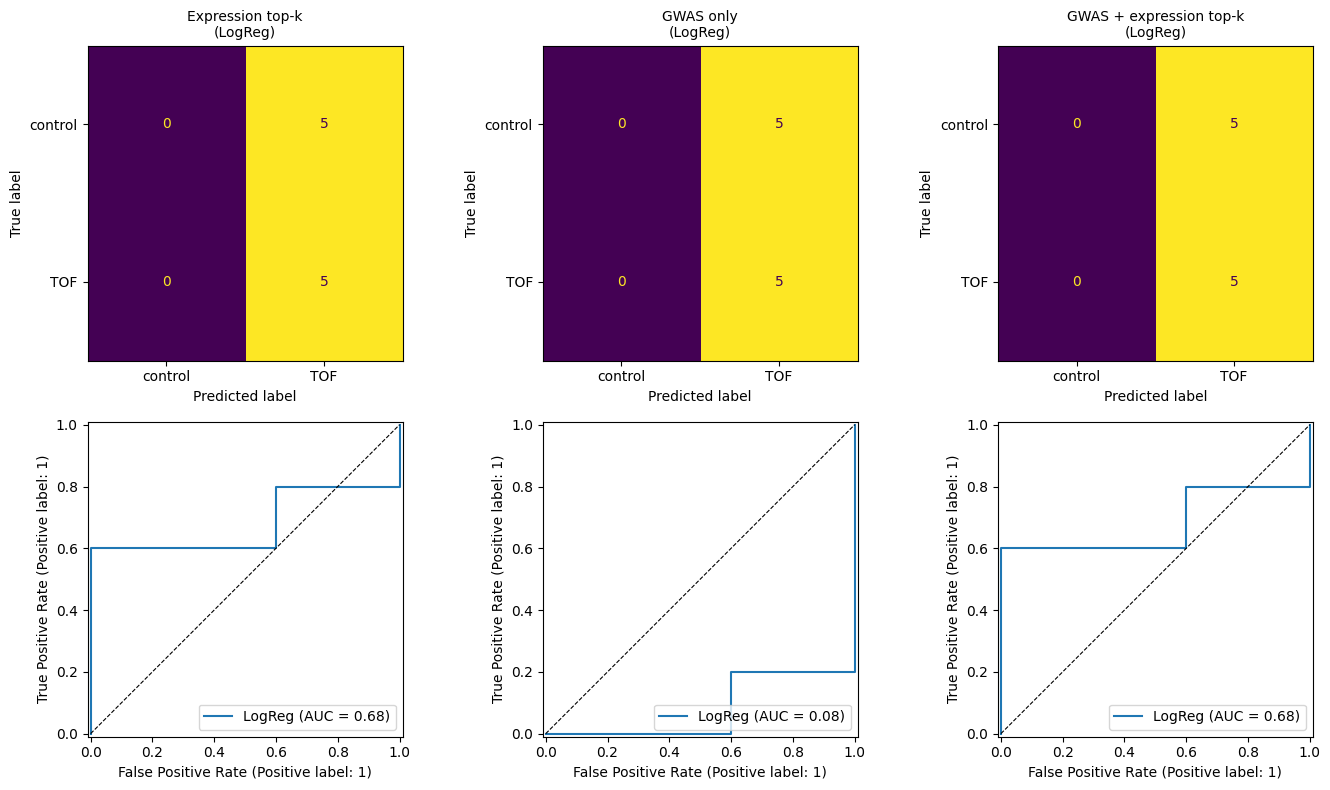


FINAL TEST on GSE217772 (5 TOF, 5 control). One wrong call = 10% accuracy.
               features  model  TN  FP  FN  TP  accuracy  balanced_acc  sensitivity  specificity  precision    F1  ROC_AUC
       Expression top-k LogReg   0   5   0   5       0.5           0.5          1.0          0.0        0.5 0.667     0.68
              GWAS only LogReg   0   5   0   5       0.5           0.5          1.0          0.0        0.5 0.667     0.08
GWAS + expression top-k LogReg   0   5   0   5       0.5           0.5          1.0          0.0        0.5 0.667     0.68


In [ ]:
# =====================================================================
# Step 13: Machine learning model (Logistic Regression + Random Forest)
# Paste as ONE new cell at the end of the notebook, after Step 11C / Step 12.
# Uses objects already in memory: train_expression, test_expression,
# gwas_selected, gene_mapping (from earlier cells).
#
# Rules followed (Module 10 slides):
#  - All tuning and gene selection happen inside cross-validation on TRAIN only.
#  - The test set (GSE217772) is evaluated ONCE, after every choice is locked.
# =====================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, cross_val_score
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
                             roc_auc_score, f1_score, precision_score, recall_score,
                             accuracy_score, balanced_accuracy_score)

import os, warnings
os.environ["PYTHONWARNINGS"] = "ignore"            # quiet divide-by-zero warnings from
warnings.filterwarnings("ignore")                  # genes that are constant within a fold

# ===== INPUT YOUR DATA HERE =====
TRAIN_EXPR = train_expression        # genes x 26 samples (GSE36761 normalized levels, filtered)
TEST_EXPR = test_expression          # same genes x 10 samples (GSE217772 raw counts)
GWAS_IDS = gwas_selected["Gene ID"].dropna().tolist()   # PTPN11, NRP1 (Ensembl IDs)
ID_TO_SYMBOL = dict(zip(gene_mapping["Gene ID"], gene_mapping["Gene Symbol"]))
K_GRID = [10, 20, 50]                # how many expression genes SelectKBest may keep
RUN_FINAL_TEST = True              # set True ONLY after you are happy with the CV results
SEED = 42
# ===== END INPUT =====

# ---------- 1. Put both datasets on the same scale ----------
# Within-sample percentile ranks: each sample's genes are ranked against each other.
# This uses no labels and no other samples, so it cannot leak test information,
# and it makes "normalized levels" (train) and "counts" (test) comparable.
def to_ranks(expr_genes_by_samples):
    X = expr_genes_by_samples.T                        # rows = samples, columns = genes
    return X.rank(axis=1, pct=True)

X_train = to_ranks(TRAIN_EXPR)
X_test = to_ranks(TEST_EXPR)[X_train.columns]          # same genes, same order

y_train = pd.Series([0 if s.startswith("NH-") else 1 for s in X_train.index],
                    index=X_train.index, name="label")
# GSE217772 column names: "treat" = TOF patient, "control" = healthy individual
y_test = pd.Series([1 if s.startswith("treat") else 0 for s in X_test.index],
                   index=X_test.index, name="label")

assert list(X_train.columns) == list(X_test.columns), "Gene columns must match"
GWAS_IDS = [g for g in GWAS_IDS if g in X_train.columns]
OTHER_IDS = [g for g in X_train.columns if g not in GWAS_IDS]
print(f"Train: {X_train.shape}  TOF={int(y_train.sum())}  control={int((y_train == 0).sum())}")
print(f"Test : {X_test.shape}  TOF={int(y_test.sum())}  control={int((y_test == 0).sum())}")
print(f"GWAS genes used: {[ID_TO_SYMBOL.get(g, g) for g in GWAS_IDS]}")

# ---------- 2. Cross-validation on TRAIN only ----------
# 4 controls -> 4 folds (each fold holds out exactly 1 control); repeat 5 times.
cv = RepeatedStratifiedKFold(n_splits=4, n_repeats=5, random_state=SEED)

dummy = DummyClassifier(strategy="most_frequent")
print(f"\nBaseline 'always TOF': CV accuracy = "
      f"{cross_val_score(dummy, X_train, y_train, cv=cv, scoring='accuracy').mean():.2f}, "
      f"balanced accuracy = "
      f"{cross_val_score(dummy, X_train, y_train, cv=cv, scoring='balanced_accuracy').mean():.2f}")

# ---------- 3. Three feature sets x two models ----------
def lr():
    return LogisticRegression(max_iter=5000, class_weight="balanced")
def rf():
    return RandomForestClassifier(class_weight="balanced", random_state=SEED)

def expression_selector():           # top-k genes by ANOVA F-test, refit inside every fold
    return SelectKBest(f_classif)

def gwas_plus_expression():          # always keep GWAS genes + top-k of the remaining genes
    return ColumnTransformer([("gwas", "passthrough", GWAS_IDS),
                              ("expr", SelectKBest(f_classif), OTHER_IDS)])

experiments = {
    ("Expression top-k", "LogReg"): (
        Pipeline([("select", expression_selector()), ("scale", StandardScaler()), ("clf", lr())]),
        {"select__k": K_GRID, "clf__C": [0.01, 0.1, 1]}),
    ("Expression top-k", "RandomForest"): (
        Pipeline([("select", expression_selector()), ("clf", rf())]),
        {"select__k": K_GRID, "clf__n_estimators": [200], "clf__min_samples_leaf": [1, 3]}),
    ("GWAS only", "LogReg"): (
        Pipeline([("pick", ColumnTransformer([("gwas", "passthrough", GWAS_IDS)])),
                  ("scale", StandardScaler()), ("clf", lr())]),
        {"clf__C": [0.01, 0.1, 1]}),
    ("GWAS only", "RandomForest"): (
        Pipeline([("pick", ColumnTransformer([("gwas", "passthrough", GWAS_IDS)])), ("clf", rf())]),
        {"clf__n_estimators": [200], "clf__min_samples_leaf": [1, 3]}),
    ("GWAS + expression top-k", "LogReg"): (
        Pipeline([("select", gwas_plus_expression()), ("scale", StandardScaler()), ("clf", lr())]),
        {"select__expr__k": K_GRID, "clf__C": [0.01, 0.1, 1]}),
    ("GWAS + expression top-k", "RandomForest"): (
        Pipeline([("select", gwas_plus_expression()), ("clf", rf())]),
        {"select__expr__k": K_GRID, "clf__n_estimators": [200], "clf__min_samples_leaf": [1, 3]}),
}

results, fitted = [], {}
for (features, model), (pipe, grid) in experiments.items():
    gs = GridSearchCV(pipe, grid, cv=cv, refit="roc_auc", n_jobs=-1,
                      scoring={"roc_auc": "roc_auc", "bal_acc": "balanced_accuracy"})
    gs.fit(X_train, y_train)                            # TRAIN only
    i = gs.best_index_
    fitted[(features, model)] = gs.best_estimator_
    results.append({"features": features, "model": model,
                    "cv_roc_auc": round(gs.cv_results_["mean_test_roc_auc"][i], 3),
                    "cv_balanced_acc": round(gs.cv_results_["mean_test_bal_acc"][i], 3),
                    "best_params": gs.best_params_})

results_df = pd.DataFrame(results)
print("\nTRAIN cross-validation (GSE36761 only; test set untouched):")
print(results_df.to_string(index=False))
results_df.to_csv("TOF_ML_CV_Results.csv", index=False)

# ---------- 4. Which genes does the best expression model use? ----------
def genes_used(pipeline):
    sel = pipeline.named_steps.get("select")
    if isinstance(sel, SelectKBest):
        return list(X_train.columns[sel.get_support()])
    if isinstance(sel, ColumnTransformer):
        expr = sel.named_transformers_["expr"]
        return GWAS_IDS + list(np.array(OTHER_IDS)[expr.get_support()])
    return GWAS_IDS

best_expr = fitted[("Expression top-k", "LogReg")]
used = genes_used(best_expr)
coefs = best_expr.named_steps["clf"].coef_[0]
gene_table = pd.DataFrame({"Gene ID": used,
                           "Symbol": [ID_TO_SYMBOL.get(g, "?") for g in used],
                           "LogReg coefficient (+ = higher in TOF)": np.round(coefs, 3)})
gene_table = gene_table.reindex(gene_table.iloc[:, 2].abs().sort_values(ascending=False).index)
print("\nGenes used by the expression LogReg model (fit on all training samples):")
print(gene_table.to_string(index=False))
gene_table.to_csv("TOF_ML_Model_Genes.csv", index=False)
print("Coefficients describe association, not causation (Module 10).")

# ---------- 5. FINAL TEST: run ONCE, after the choices above are locked ----------
def evaluate_on_test(features, model, threshold=0.5):
    pipe = fitted[(features, model)]
    proba = pipe.predict_proba(X_test)[:, 1]            # P(TOF)
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    row = {"features": features, "model": model, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
           "accuracy": accuracy_score(y_test, pred),
           "balanced_acc": balanced_accuracy_score(y_test, pred),
           "sensitivity": recall_score(y_test, pred, zero_division=0),
           "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
           "precision": precision_score(y_test, pred, zero_division=0),
           "F1": f1_score(y_test, pred, zero_division=0),
           "ROC_AUC": roc_auc_score(y_test, proba)}
    return row, proba, pred

if RUN_FINAL_TEST:
    rows = []
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    for col, features in enumerate(["Expression top-k", "GWAS only", "GWAS + expression top-k"]):
        # pick the model family for each feature set by TRAIN CV only
        sub = results_df[results_df.features == features]
        model = sub.sort_values(["cv_roc_auc", "cv_balanced_acc"], ascending=False).iloc[0]["model"]
        row, proba, pred = evaluate_on_test(features, model)
        rows.append(row)
        ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["control", "TOF"],
                                                ax=axes[0, col], colorbar=False)
        axes[0, col].set_title(f"{features}\n({model})", fontsize=10)
        RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1, col], name=model)
        axes[1, col].plot([0, 1], [0, 1], "k--", lw=0.8)
    plt.tight_layout()
    plt.savefig("TOF_ML_Test_Results.png", dpi=300, bbox_inches="tight")
    plt.show()
    test_df = pd.DataFrame(rows).round(3)
    print("\nFINAL TEST on GSE217772 (5 TOF, 5 control). One wrong call = 10% accuracy.")
    print(test_df.to_string(index=False))
    test_df.to_csv("TOF_ML_Test_Results.csv", index=False)
else:
    print("\nFinal test NOT run (RUN_FINAL_TEST = False). Review the CV table first.")

In [ ]:
# =====================================================================
# Step 14: Post-hoc diagnostics. Explains WHY the locked model failed on GSE217772.
# This does NOT change or replace the Step 13 test result. Report it as post-hoc.
# Run after Step 13 (uses fitted, genes_used, X_train, X_test, y_train, y_test, ID_TO_SYMBOL).
# Values are within-sample percentile ranks (0 = lowest gene in that sample, 1 = highest).
# =====================================================================
import pandas as pd

SYMBOL_TO_ID = {sym: gid for gid, sym in ID_TO_SYMBOL.items()}
model = fitted[("Expression top-k", "LogReg")]

# ---------- 1. Predicted P(TOF) for each test sample ----------
probs = pd.DataFrame({
    "true group": y_test.map({1: "TOF", 0: "control"}),
    "P(TOF)": model.predict_proba(X_test)[:, 1].round(3),
}).sort_values("P(TOF)")
print("Predicted probability of TOF, test samples (threshold = 0.5):")
print(probs.to_string())

# ---------- 2. Do the model's genes behave the same way in both datasets? ----------
extra = [SYMBOL_TO_ID[s] for s in ["TNNI1", "TNNI3"]
         if s in SYMBOL_TO_ID and SYMBOL_TO_ID[s] in X_train.columns]
rows = []
for g in dict.fromkeys(genes_used(model) + extra):     # keeps order, drops repeats
    tr_tof, tr_ctl = X_train.loc[y_train == 1, g].mean(), X_train.loc[y_train == 0, g].mean()
    te_tof, te_ctl = X_test.loc[y_test == 1, g].mean(), X_test.loc[y_test == 0, g].mean()
    rows.append({
        "gene": ID_TO_SYMBOL.get(g, g),
        "train TOF": round(tr_tof, 2), "train ctl": round(tr_ctl, 2),
        "test TOF": round(te_tof, 2), "test ctl": round(te_ctl, 2),
        "same direction": (tr_tof - tr_ctl > 0) == (te_tof - te_ctl > 0),
        "test ctl looks like train": "TOF" if abs(te_ctl - tr_tof) < abs(te_ctl - tr_ctl) else "control",
    })
diag = pd.DataFrame(rows)
print("\nMean percentile rank by group (model genes, plus TNNI1/TNNI3 for the age check):")
print(diag.to_string(index=False))
print(f"\nGenes with the same TOF-vs-control direction in both datasets: "
      f"{int(diag['same direction'].sum())} of {len(diag)}")
print(f"Genes where TEST controls sit closer to TRAIN TOF than to TRAIN controls: "
      f"{int((diag['test ctl looks like train'] == 'TOF').sum())} of {len(diag)}")
diag.to_csv("TOF_ML_PostHoc_Diagnostics.csv", index=False)


Predicted probability of TOF, test samples (threshold = 0.5):
         true group  P(TOF)
treat3          TOF   0.608
control2    control   0.631
control4    control   0.663
treat4          TOF   0.712
control5    control   0.720
control3    control   0.723
control1    control   0.730
treat5          TOF   0.745
treat2          TOF   0.756
treat1          TOF   0.765

Mean percentile rank by group (model genes, plus TNNI1/TNNI3 for the age check):
  gene  train TOF  train ctl  test TOF  test ctl  same direction test ctl looks like train
CHRDL2       0.10       0.77      0.18      0.16           False                       TOF
 NALCN       0.02       0.37      0.07      0.19            True                       TOF
 PANX1       0.36       0.73      0.42      0.39           False                       TOF
FIBCD1       0.06       0.34      0.05      0.06            True                       TOF
  NREP       0.96       0.42      0.95      0.96           False                       TOF
 T

t

In [ ]:

# ============================================================
# STEP 13: Does GWAS-informed gene selection improve prediction?
# Training: GSE36761
# Independent testing: GSE217772
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

from sklearn.model_selection import (
    GridSearchCV,
    RepeatedStratifiedKFold
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)


# 1. PREPARE DATA


TRAIN_EXPR = train_expression
TEST_EXPR = test_expression

# Convert to samples x genes
X_train = TRAIN_EXPR.T.copy()
X_test = TEST_EXPR.T.copy()

# Make sure genes match and are in the same order
X_test = X_test[X_train.columns]

# Create training labels
# 0 = control
# 1 = TOF

y_train = pd.Series(
    [0 if s.startswith("NH-") else 1 for s in X_train.index],
    index=X_train.index
)

# Create independent testing labels
# 0 = control
# 1 = TOF

y_test = pd.Series(
    [1 if s.lower().startswith("treat") else 0
     for s in X_test.index],
    index=X_test.index
)

print("Training samples:", X_train.shape[0])
print("Training genes:", X_train.shape[1])

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting samples:", X_test.shape[0])
print("Testing labels:")
print(y_test.value_counts())

assert y_train.nunique() == 2, "Training labels must contain both classes."
assert y_test.nunique() == 2, "Testing labels must contain both classes."
assert X_train.shape[1] == X_test.shape[1]


# ------------------------------------------------------------
# 2. PUT DATASETS ON A COMPARABLE SCALE


X_train = X_train.rank(axis=1, pct=True)
X_test = X_test.rank(axis=1, pct=True)

# ------------------------------------------------------------
# 3. IDENTIFY GWAS-ASSOCIATED GENES


ID_TO_SYMBOL = dict(
    zip(gene_mapping["Gene ID"], gene_mapping["Gene Symbol"])
)

GWAS_IDS = (
    gwas_selected["Gene ID"]
    .dropna()
    .drop_duplicates()
    .tolist()
)

# Keep only GWAS genes available in both datasets
GWAS_IDS = [
    gene for gene in GWAS_IDS
    if gene in X_train.columns and gene in X_test.columns
]

if len(GWAS_IDS) == 0:
    raise ValueError(
        "No GWAS candidate genes were found in both datasets. "
        "Check Step 11C and the gene ID mapping."
    )

# Separate remaining genes from GWAS genes
OTHER_IDS = [
    gene for gene in X_train.columns
    if gene not in GWAS_IDS
]

print("\nGWAS genes included:")
print([ID_TO_SYMBOL.get(g, g) for g in GWAS_IDS])

print("Number of GWAS genes:", len(GWAS_IDS))
print("Number of other genes:", len(OTHER_IDS))


Training samples: 26
Training genes: 14985

Training labels:
1    22
0     4
Name: count, dtype: int64

Testing samples: 10
Testing labels:
1    5
0    5
Name: count, dtype: int64

GWAS genes included:
['PTPN11', 'NRP1']
Number of GWAS genes: 2
Number of other genes: 14983


In [ ]:

# 4. SET UP CROSS-VALIDATION


cv = RepeatedStratifiedKFold(
    n_splits=4,
    n_repeats=5,
    random_state=42
)

# Select only values of k that are possible
K_GRID = [
    k for k in [10, 20, 50]
    if k <= len(OTHER_IDS)
]

if not K_GRID:
    raise ValueError("Not enough non-GWAS genes for feature selection.")

print("\nExpression feature selection values:", K_GRID)


# ------------------------------------------------------------
# 5. DEFINE MACHINE LEARNING MODELS


def logistic_regression():

    return LogisticRegression(
        max_iter=5000,
        class_weight="balanced"
    )


def random_forest():

    return RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    )




Expression feature selection values: [10, 20, 50]


In [ ]:

# ------------------------------------------------------------
# 6. DEFINE THREE FEATURE SELECTION STRATEGIES


# Strategy A: Select genes based on expression differences
expression_selector = SelectKBest(f_classif)

# Strategy B: Use only GWAS genes
gwas_selector = ColumnTransformer(
    [("gwas", "passthrough", GWAS_IDS)]
)

# Strategy C: Always retain GWAS genes and select
# additional expression-associated genes.

combined_selector = ColumnTransformer([
    ("gwas", "passthrough", GWAS_IDS),
    ("expression", SelectKBest(f_classif), OTHER_IDS)
])


# ------------------------------------------------------------
# 7. BUILD SIX EXPERIMENTS


experiments = {

    # Expression-selected genes
    ("Expression genes", "Logistic Regression"): (
        Pipeline([
            ("select", SelectKBest(f_classif)),
            ("scale", StandardScaler()),
            ("model", logistic_regression())
        ]),
        {
            "select__k": K_GRID,
            "model__C": [0.01, 0.1, 1]
        }
    ),

    ("Expression genes", "Random Forest"): (
        Pipeline([
            ("select", SelectKBest(f_classif)),
            ("model", random_forest())
        ]),
        {
            "select__k": K_GRID,
            "model__min_samples_leaf": [1, 3]
        }
    ),

    # GWAS genes only
    ("GWAS genes only", "Logistic Regression"): (
        Pipeline([
            ("select", gwas_selector),
            ("scale", StandardScaler()),
            ("model", logistic_regression())
        ]),
        {
            "model__C": [0.01, 0.1, 1]
        }
    ),

    ("GWAS genes only", "Random Forest"): (
        Pipeline([
            ("select", gwas_selector),
            ("model", random_forest())
        ]),
        {
            "model__min_samples_leaf": [1, 3]
        }
    ),

    # GWAS genes + expression-selected genes
    ("GWAS + Expression", "Logistic Regression"): (
        Pipeline([
            ("select", combined_selector),
            ("scale", StandardScaler()),
            ("model", logistic_regression())
        ]),
        {
            "select__expression__k": K_GRID,
            "model__C": [0.01, 0.1, 1]
        }
    ),

    ("GWAS + Expression", "Random Forest"): (
        Pipeline([
            ("select", combined_selector),
            ("model", random_forest())
        ]),
        {
            "select__expression__k": K_GRID,
            "model__min_samples_leaf": [1, 3]
        }
    )
}


In [ ]:


# ------------------------------------------------------------
# 8. TRAIN AND COMPARE MODELS USING CROSS-VALIDATION
# ------------------------------------------------------------

results = []
fitted_models = {}

for (feature_type, model_name), (pipeline, parameters) in experiments.items():

    print("\nTraining:", feature_type, "-", model_name)

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameters,
        scoring={
            "roc_auc": "roc_auc",
            "balanced_accuracy": "balanced_accuracy"
        },
        refit="roc_auc",
        cv=cv,
        n_jobs=-1
    )

    # Only training data is used here
    search.fit(X_train, y_train)

    best_index = search.best_index_

    fitted_models[(feature_type, model_name)] = search.best_estimator_

    results.append({
        "Feature Selection": feature_type,
        "Model": model_name,
        "CV ROC-AUC": search.cv_results_[
            "mean_test_roc_auc"
        ][best_index],
        "CV Balanced Accuracy": search.cv_results_[
            "mean_test_balanced_accuracy"
        ][best_index],
        "Best Parameters": search.best_params_
    })


# Display cross-validation results
cv_results = pd.DataFrame(results)

print("\n========== CROSS-VALIDATION RESULTS ==========")

display(
    cv_results.round(3)
)

cv_results.to_csv(
    "TOF_GWAS_CV_Results.csv",
    index=False
)


# ------------------------------------------------------------
# 9. ESTABLISH A BASELINE
# ------------------------------------------------------------

baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_train)

print("\nBaseline model:")
print(
    "Training balanced accuracy:",
    round(
        balanced_accuracy_score(
            y_train, baseline_predictions
        ), 3
    )
)


# ------------------------------------------------------------
# 10. INDEPENDENT TESTING
# ------------------------------------------------------------

# Select the best model within each feature strategy
# using training cross-validation only.

test_results = []
test_predictions = {}

for feature_type in [
    "Expression genes",
    "GWAS genes only",
    "GWAS + Expression"
]:

    subset = cv_results[
        cv_results["Feature Selection"] == feature_type
    ]

    best_model_name = (
        subset.sort_values(
            ["CV ROC-AUC", "CV Balanced Accuracy"],
            ascending=False
        ).iloc[0]["Model"]
    )

    model = fitted_models[
        (feature_type, best_model_name)
    ]

    # Predict independent test samples
    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    test_results.append({
        "Feature Selection": feature_type,
        "Model": best_model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Sensitivity": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn
    })

    test_predictions[feature_type] = predictions




Training: Expression genes - Logistic Regression

Training: Expression genes - Random Forest

Training: GWAS genes only - Logistic Regression

Training: GWAS genes only - Random Forest

Training: GWAS + Expression - Logistic Regression

Training: GWAS + Expression - Random Forest

========== CROSS-VALIDATION RESULTS ==========


,Feature Selection,Model,CV ROC-AUC,CV Balanced Accuracy,Best Parameters
0,Expression genes,Logistic Regression,1.000,1.000,"{'model__C': 0.01, 'select__k': 10}"
1,Expression genes,Random Forest,1.000,0.975,"{'model__min_samples_leaf': 1, 'select__k': 10}"
2,GWAS genes only,Logistic Regression,0.605,0.589,{'model__C': 1}
3,GWAS genes only,Random Forest,0.496,0.459,{'model__min_samples_leaf': 3}
4,GWAS + Expression,Logistic Regression,1.000,1.000,"{'model__C': 0.01, 'select__expression__k': 10}"
5,GWAS + Expression,Random Forest,1.000,0.975,"{'model__min_samples_leaf': 1, 'select__expres..."



Baseline model:
Training balanced accuracy: 0.5



========== INDEPENDENT TEST RESULTS ==========


,Feature Selection,Model,Accuracy,Balanced Accuracy,ROC-AUC,Sensitivity,Specificity,TP,TN,FP,FN
0,Expression genes,Logistic Regression,0.5,0.5,0.68,1.0,0.0,5,0,5,0
1,GWAS genes only,Logistic Regression,0.5,0.5,0.08,1.0,0.0,5,0,5,0
2,GWAS + Expression,Logistic Regression,0.5,0.5,0.68,1.0,0.0,5,0,5,0


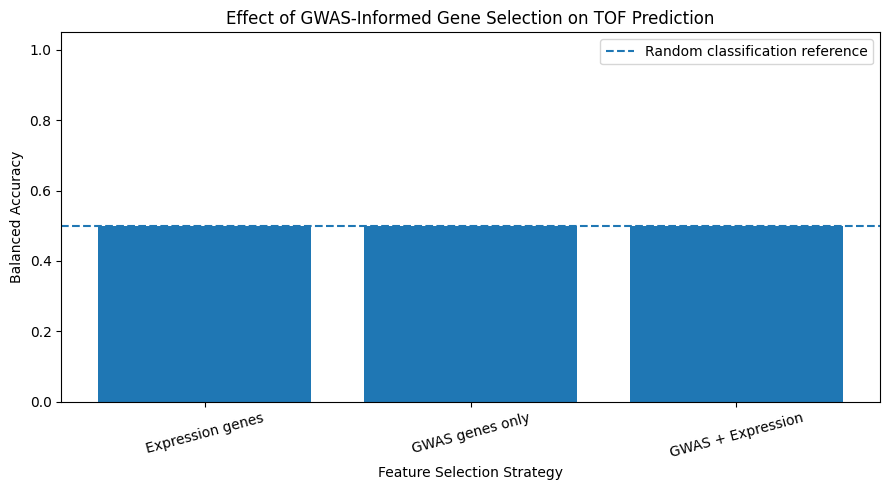

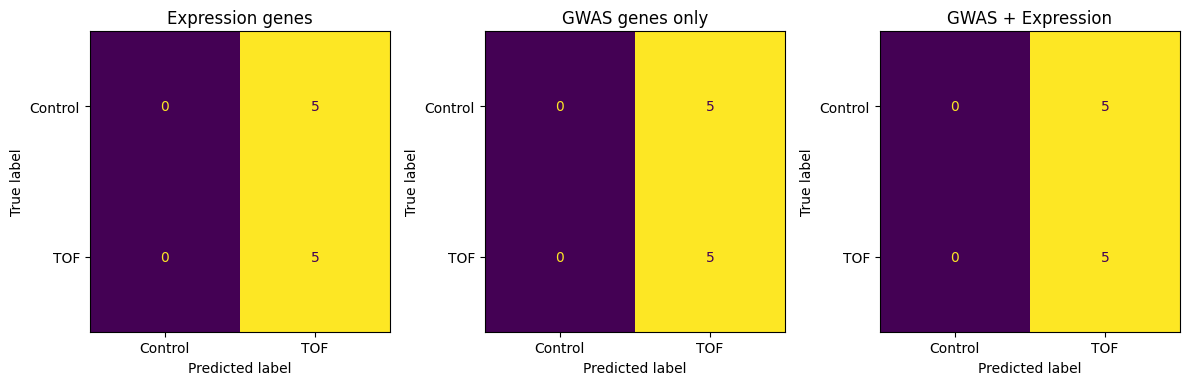

In [ ]:

# ------------------------------------------------------------
# 11. DISPLAY FINAL RESULTS
# ------------------------------------------------------------

test_results_df = pd.DataFrame(test_results)

print("\n========== INDEPENDENT TEST RESULTS ==========")

display(
    test_results_df.round(3)
)

test_results_df.to_csv(
    "TOF_GWAS_Test_Results.csv",
    index=False
)


# ------------------------------------------------------------
# 12. VISUALIZE MODEL PERFORMANCE
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    test_results_df["Feature Selection"],
    test_results_df["Balanced Accuracy"]
)

plt.axhline(
    0.5,
    linestyle="--",
    label="Random classification reference"
)

plt.ylabel("Balanced Accuracy")
plt.xlabel("Feature Selection Strategy")
plt.title("Effect of GWAS-Informed Gene Selection on TOF Prediction")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 13. CONFUSION MATRICES
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, feature_type in zip(
    axes,
    [
        "Expression genes",
        "GWAS genes only",
        "GWAS + Expression"
    ]
):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        test_predictions[feature_type],
        display_labels=["Control", "TOF"],
        ax=ax,
        colorbar=False
    )

    ax.set_title(feature_type)

plt.tight_layout()
plt.show()



In [ ]:

# ------------------------------------------------------------
# 14. COMPARE WHETHER GWAS IMPROVED PREDICTION
# ------------------------------------------------------------

expression_score = test_results_df.loc[
    test_results_df["Feature Selection"] == "Expression genes",
    "Balanced Accuracy"
].iloc[0]

combined_score = test_results_df.loc[
    test_results_df["Feature Selection"] == "GWAS + Expression",
    "Balanced Accuracy"
].iloc[0]

difference = combined_score - expression_score

print("\n========== GWAS IMPROVEMENT ==========")

print(
    "Expression-only balanced accuracy:",
    round(expression_score, 3)
)

print(
    "GWAS + expression balanced accuracy:",
    round(combined_score, 3)
)

print(
    "Difference:",
    round(difference, 3)
)

if difference > 0:
    print(
        "\nGWAS-informed feature selection improved "
        "independent test balanced accuracy."
    )

elif difference < 0:
    print(
        "\nGWAS-informed feature selection decreased "
        "independent test balanced accuracy."
    )

else:
    print(
        "\nGWAS-informed feature selection produced "
        "the same independent test balanced accuracy."
    )



========== GWAS IMPROVEMENT ==========
Expression-only balanced accuracy: 0.5
GWAS + expression balanced accuracy: 0.5
Difference: 0.0

GWAS-informed feature selection produced the same independent test balanced accuracy.


FIGURE 3: PCA RESULTS
----------------------------
PC1 variance: 41.26%
PC2 variance: 14.36%
Total variance: 55.61%


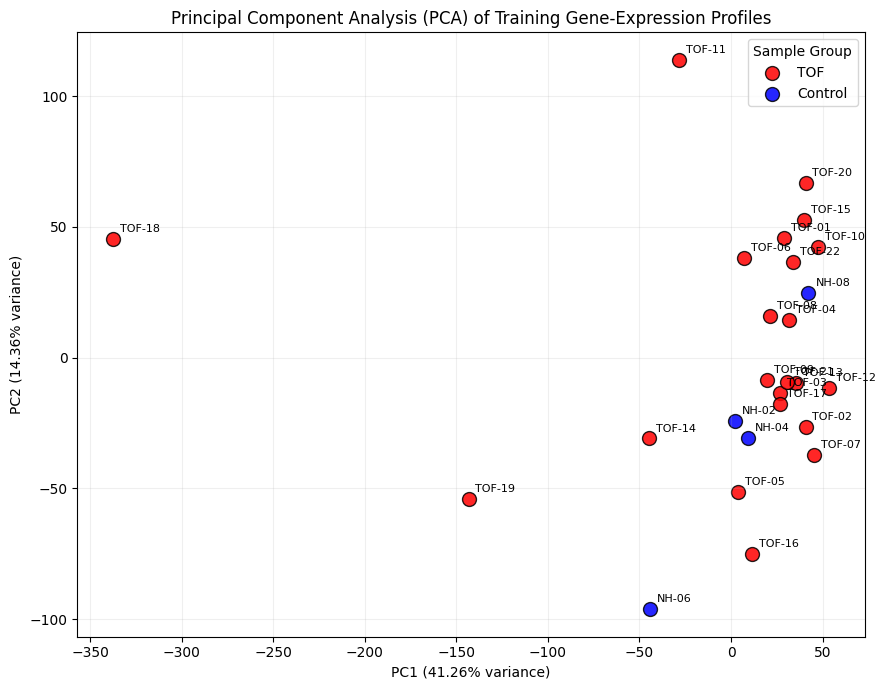

,PC1,PC2,Condition
NH-02,2.184,-24.127,Control
NH-04,9.113,-30.815,Control
NH-06,-44.329,-96.210,Control
NH-08,42.267,24.591,Control
TOF-04,31.859,14.607,TOF
TOF-05,3.982,-51.528,TOF
TOF-18,-337.410,45.255,TOF
TOF-19,-143.335,-54.139,TOF
TOF-07,45.347,-37.248,TOF
TOF-08,21.495,15.857,TOF


In [ ]:

# ============================================================
# FIGURE 3: PCA OF TRAINING GENE-EXPRESSION PROFILES
# TOF Project: GSE36761
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Prepare training expression matrix
# Rows = samples, Columns = genes

X_train_pca = train_expression.T.copy()

# 2. Log2 transformation
X_train_log = np.log2(
    X_train_pca.clip(lower=0) + 1
)

# 3. Standardize gene expression
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_log)

# 4. Perform PCA
pca = PCA(n_components=2)

pca_coordinates = pca.fit_transform(X_train_scaled)

# 5. Create PCA results table
pca_results = pd.DataFrame(
    pca_coordinates,
    columns=["PC1", "PC2"],
    index=X_train_pca.index
)

# 6. Assign sample conditions
pca_results["Condition"] = [
    "Control" if sample.startswith("NH-") else "TOF"
    for sample in pca_results.index
]

# 7. Calculate explained variance
pc1 = pca.explained_variance_ratio_[0] * 100
pc2 = pca.explained_variance_ratio_[1] * 100

print("FIGURE 3: PCA RESULTS")
print("----------------------------")
print(f"PC1 variance: {pc1:.2f}%")
print(f"PC2 variance: {pc2:.2f}%")
print(f"Total variance: {pc1 + pc2:.2f}%")

# 8. Plot PCA
plt.figure(figsize=(9, 7))

for condition, color in [
    ("TOF", "red"),
    ("Control", "blue")
]:

    subset = pca_results[
        pca_results["Condition"] == condition
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        color=color,
        label=condition,
        s=100,
        edgecolors="black",
        alpha=0.85
    )

    # Label individual samples
    for sample, row in subset.iterrows():
        plt.annotate(
            sample,
            (row["PC1"], row["PC2"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

plt.xlabel(f"PC1 ({pc1:.2f}% variance)")
plt.ylabel(f"PC2 ({pc2:.2f}% variance)")

plt.title(
    "Principal Component Analysis (PCA) "
    "of Training Gene-Expression Profiles"
)

plt.legend(title="Sample Group")
plt.grid(alpha=0.2)
plt.tight_layout()

# 9. Save figure
plt.savefig(
    "Figure_3_Training_PCA.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 10. Display PCA coordinates
display(pca_results.round(3))

# 11. Save numerical results
pca_results.to_csv("Figure_3_PCA_Coordinates.csv")

